In [6]:


import pandas as pd
import numpy as np

import sympy as sp
# import numba as nb
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm
from sympy import exp, sin
import time
from sklearn.neighbors import NearestNeighbors
import cProfile
from scipy.spatial import cKDTree
from numpy import array
import faiss

# Define the CustomStandardScaler class as previously mentioned
class CustomStandardScaler:
    def __init__(self):
        self.mean_ = None
        self.scale_ = None

    def fit(self, X):
        """Compute the mean and standard deviation of the features."""
        self.mean_ = np.mean(X, axis=0)
        self.scale_ = np.std(X, axis=0)
        return self

    def transform(self, X):
        """Scale features by removing the mean and scaling to unit variance."""
        if self.mean_ is None or self.scale_ is None:
            raise RuntimeError("You must fit the scaler before transforming data.")
        return (X - self.mean_) / self.scale_

    def inverse_transform(self, X_standardized):
        """Transform data back to the original scale."""
        if self.mean_ is None or self.scale_ is None:
            raise RuntimeError("You must fit the scaler before inverse transforming data.")
        return (X_standardized * self.scale_) + self.mean_

    def fit_transform(self, X):
        """Fit to the data and then transform it."""
        return self.fit(X).transform(X)


import pandas as pd
import numpy as np

def get_fitted_scaler_from_csv_both(file_path, target_col, scaler_type='standard'):
    """
    Reads a CSV file, scales the features, and returns a fitted CustomStandardScaler.

    Parameters:
    - file_path: str, the path to the CSV file.
    - target_col: str, the name of the target column.
    - scaler_type: str, the type of scaler to use ('standard').

    Returns:
    - CustomStandardScaler: Fitted scaler object.
    - pd.DataFrame: DataFrame with scaled features and target.
    """
    # Load the CSV file into a DataFrame
    if file_path.endswith('.xlsx'):
        df = pd.read_excel(file_path)
    elif file_path.endswith('.txt') or file_path.endswith('.csv'):
        df = pd.read_csv(file_path, delim_whitespace=True)
    else:
        raise ValueError("Unsupported file format. Please use .txt or .xlsx files.")

    # Initialize the appropriate scaler
    if scaler_type == 'standard':
        feature_scaler = CustomStandardScaler()
    else:
        raise ValueError(f"Scaler type '{scaler_type}' is not supported. Choose 'standard'.")

    # Separate the features (X) and target (y)
    X = df.drop(columns=[target_col])
    y = df[target_col]

    # Select only numeric columns for scaling
    numeric_features = X.select_dtypes(include=[np.number])

    # Fit the scaler to the numeric features
    feature_scaler.fit(numeric_features)

    # Scale the numeric features
    X_scaled_numeric = feature_scaler.transform(numeric_features)

    # Convert scaled numeric features back to DataFrame
    X_scaled_numeric_df = pd.DataFrame(X_scaled_numeric, columns=numeric_features.columns, index=X.index)

    # Concatenate scaled numeric features with non-numeric features
    non_numeric_features = X.drop(columns=numeric_features.columns)
    X_scaled_df = pd.concat([X_scaled_numeric_df, non_numeric_features], axis=1)

    # Scale the target (y)
    y_2d = np.reshape(y.values, (y.shape[0], 1))
    target_scaler = CustomStandardScaler().fit(y_2d)
    y_scaled = target_scaler.transform(y_2d).flatten()

    # Add the scaled target column
    X_scaled_df[target_col] = y_scaled

    return feature_scaler, target_scaler, X_scaled_df


def get_fitted_scaler_from_csv(file_path, target_col, scaler_type='standard'):
    """
    Reads a CSV file, scales the features, and returns a fitted CustomStandardScaler.

    Parameters:
    - file_path: str, the path to the CSV file.
    - target_col: str, the name of the target column.
    - scaler_type: str, the type of scaler to use ('standard').

    Returns:
    - CustomStandardScaler: Fitted scaler object.
    - pd.DataFrame: DataFrame with scaled features and target.
    """
    # Load the CSV file into a DataFrame
    if file_path.endswith('.xlsx'):
        df = pd.read_excel(file_path)
    elif file_path.endswith('.txt') or file_path.endswith('.csv'):
        df = pd.read_csv(file_path, delim_whitespace=True)
    else:
        print("Unsupported file format. Please use .txt or .xlsx files.")
        return

    # Initialize the appropriate scaler
    if scaler_type == 'standard':
        feature_scaler = CustomStandardScaler()
    else:
        raise ValueError(f"Scaler type '{scaler_type}' is not supported. Choose 'standard'.")

    # Separate the features (X) and target (y)
    X = df.drop(columns=[target_col])
    y = df[target_col]

    # Select only numeric columns for scaling
    numeric_features = X.select_dtypes(include=[np.number])

    # Fit the scaler to the numeric features
    feature_scaler.fit(numeric_features)

    # Scale the numeric features
    X_scaled_numeric = feature_scaler.transform(numeric_features)

    # Convert scaled numeric features back to DataFrame
    X_scaled_numeric_df = pd.DataFrame(X_scaled_numeric, columns=numeric_features.columns, index=X.index)

    # Concatenate scaled numeric features with non-numeric features
    non_numeric_features = X.drop(columns=numeric_features.columns)
    X_scaled_df = pd.concat([X_scaled_numeric_df, non_numeric_features], axis=1)

    # Scale the target (y)
    y_2d = np.reshape(y.values, (y.shape[0], 1))
    target_scaler = CustomStandardScaler().fit(y_2d)
    y_scaled = target_scaler.transform(y_2d).flatten()

    # Add the scaled target column
    X_scaled_df[target_col] = y_scaled

    return feature_scaler, X_scaled_df

# Example usage
file_path = "/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv"
target_col = 'Gibbs_energy'
scaler, scaled_df = get_fitted_scaler_from_csv(file_path, target_col)

COLUMN_TO_VAR = {
    'Temperature_[K]': 'x0',
    'Mass_fraction_Nb': 'x1',
    'Mass_fraction_Al': 'x2',
    'Mass_fraction_Ti': 'x3',
    "Mass_fraction_Mo": 'x4',
    'Mass_fraction_Fe': 'x5',
    'Mass_fraction_Cr': 'x6',
    'Mass_fraction_Ni': 'x7',
    'temp_class': 'x8'
}

def clean_point(query_point):
    # Convert the tuple to a list
    point_list = list(query_point)
    
    # Replace NaN values with 0 and remove -inf and +inf values
    cleaned_point_list = [
        0 if np.isnan(val) else val 
        for val in point_list 
        if not np.isinf(val)
    ]
    
    # Convert the cleaned list back to a tuple
    cleaned_point_tuple = tuple(cleaned_point_list)
    
    return cleaned_point_tuple

def clean_query_point(query_point):
    # Convert the tuple to a list
    point_list = list(query_point)
    
    # Filter out NaN, -inf, and +inf values
    cleaned_point_list = [val for val in point_list if not (np.isnan(val) or np.isinf(val))]
    
    # Convert the cleaned list back to a tuple
    cleaned_point_tuple = tuple(cleaned_point_list)
    
    return cleaned_point_tuple

def get_scaled(point: tuple, scaler: CustomStandardScaler, point_order = [
    'Temperature_[K]',
    'Mass_fraction_Nb',
    'Mass_fraction_Al',
    'Mass_fraction_Ti',
    'Mass_fraction_Mo',
    'Mass_fraction_Fe',
    'Mass_fraction_Cr',
    'Mass_fraction_Ni']):
    
    # Create a DataFrame with the new point
    new_point_df = pd.DataFrame([point], columns=point_order)

    scaled_features = scaler.transform(new_point_df)
    
    # Rename columns and reorder
    scaled_features = scaled_features[point_order].rename(columns=COLUMN_TO_VAR)


    # Create a list of DataPoint instances
    # ref_data_points = []
    
    for idx, row in scaled_features.iterrows():
        return tuple(row)  # Convert row to tuple
        # temp_class = df.loc[idx, 'temp_class']  # Access temp_class from the original DataFrame
        # query = DataPoint(point=point, index=idx, temp_class=temp_class)
        
    # return query
    
from dataclasses import dataclass
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Define the dataclass
@dataclass
class DataPoint:
    '''
    Point is in the format: 
    'Temperature_[K]': 'x0',
    'Mass_fraction_Nb': 'x1',
    'Mass_fraction_Al': 'x2',
    'Mass_fraction_Ti': 'x3',
    "Mass_fraction_Mo": 'x4',
    'Mass_fraction_Fe': 'x5',
    'Mass_fraction_Cr': 'x6',
    'Mass_fraction_Ni': 'x7',
    '''
    point: tuple
    index: int
    temp_class: str
    gibbs_energy: float = None
    
    


# Load the file
file_path = "/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv"

if file_path.endswith('.xlsx'):
    df = pd.read_excel(file_path)
elif file_path.endswith('.txt') or file_path.endswith('.csv'):
    df = pd.read_csv(file_path, delim_whitespace=True)
else:
    print("Unsupported file format. Please use .txt or .xlsx files.")


# Scaling the dataframe
def scale_dataframe(df, column_to_scale):
    scaler = StandardScaler()
    df[column_to_scale] = scaler.fit_transform(df[[column_to_scale]])
    return df

df = scale_dataframe(df, 'Gibbs_energy')

# Calculate the number of rows to sample (80% of the DataFrame)
sample_size = int(len(df) * 0.8)

# Randomly sample 80% of the rows
reference_df = df.sample(n=sample_size, random_state=42)

# print(reference_df.head)

# Specify the new order of columns
new_order = [
    'Temperature_[K]',
    'Mass_fraction_Nb',
    'Mass_fraction_Al',
    'Mass_fraction_Ti',
    'Mass_fraction_Mo',
    'Mass_fraction_Fe',
    'Mass_fraction_Cr',
    'Mass_fraction_Ni'
]

# Rename columns and reorder
COLUMN_TO_VAR = {
    'Temperature_[K]': 'x0',
    'Mass_fraction_Nb': 'x1',
    'Mass_fraction_Al': 'x2',
    'Mass_fraction_Ti': 'x3',
    'Mass_fraction_Mo': 'x4',
    'Mass_fraction_Fe': 'x5',
    'Mass_fraction_Cr': 'x6',
    'Mass_fraction_Ni': 'x7'
}
reference_df = reference_df[new_order].rename(columns=COLUMN_TO_VAR)

# print(reference_df.head)

# Create a list of DataPoint instances
class DataPoint:
    def __init__(self, point, index, temp_class, gibbs_energy):
        self.point = point
        self.index = index
        self.temp_class = temp_class
        self.gibbs_energy = gibbs_energy

scaled_ref_data_points = []
for idx, row in reference_df.iterrows():
    point = tuple(row)  # Convert row to tuple
    temp_class = df.loc[idx, 'temp_class']  # Access temp_class from the original DataFrame
    gibbs = df.loc[idx, 'Gibbs_energy']
    scaled_point = np.array(clean_point(get_scaled(point, scaler)))
    scaled_ref_data_points.append(DataPoint(point=scaled_point, index=idx, temp_class=temp_class, gibbs_energy=gibbs))

sampled_indices = reference_df.index

# Select the remaining 20% of the rows that were not sampled
remaining_df = df.drop(sampled_indices)

# Rename columns and reorder for consistency
remaining_df = remaining_df[new_order].rename(columns=COLUMN_TO_VAR)


# Create a list of DataPoint instances for the remaining 20%
scaled_remaining_data_points = []
for idx, row in remaining_df.iterrows():
    point = tuple(row)  # Convert row to tuple
    temp_class = df.loc[idx, 'temp_class']  # Access temp_class from the original DataFrame
    gibbs = df.loc[idx, 'Gibbs_energy']
    scaled_point = np.array(clean_point(get_scaled(point, scaler)))
    scaled_remaining_data_points.append(DataPoint(point=scaled_point, index=idx, temp_class=temp_class, gibbs_energy=gibbs))

        
        
# Function to compute the symbolic gradient of an expression with respect to each variable
def symbolic_gradient(expression, variables):
    return [sp.diff(expression, var) for var in variables]

x0, x1, x2, x3, x4, x5, x6, x7 = sp.symbols('x0 x1 x2 x3 x4 x5 x6 x7')
filter_variables = [x0, x1, x2, x3, x4, x5, x6, x7]


relevant_variables = [x0, x1, x2, x3, x4, x5, x6, x7]


symbolic_regression_equations = {
    'nb': 1.03270862299102**(x0 - 0.147339617213465)*(-x0 + 0.021397095*x1**2 - 0.08920332*x1 + 0.0116672822289432),
    'al': (0.488004**x2*0.37150496 - x0 - 0.0363654030181225*(x0 + x2*(-0.19069715))**2 - 1*0.4359865)*0.9507373,
    'ti': (-x0 + 0.24438056*(0.54978156**x3 - 1*1.0615255))/(0.96852654**(x0 - sin(exp(x3 - 0.88373876)))),
    'mo': -x0 + (-x0**2 + sin(-1.1895381**(x0 + 0.99361753) + x4) + 1.51626345732225)*0.03205326,
    'fe': 1.0334572**x0*(-x0 + 0.23702882/(x5 + exp(2*(1.0334572**x5)**(x0 - 1*(-0.49997815))))),
    'cr': -x0 + (-x0**2 + x6*sin(sin(0.8701099**(x0 - x6))) - 0.056781147)*0.032317404 + 0.032317404
    # Add other elements...
}


# 0.00041702 ± 0.00228150
simplified_regression_equations_chat = {
    'nb': 1.0327**(x0 - 0.1473) * (-x0 + 0.0214 * x1**2 - 0.0892 * x1 + 0.0117),
    'al': 0.1710 * 0.4880**x2 - 0.951 * x0 - 0.0346 * x0**2 + 0.0132 * x0 * x2 - 0.0012 * x2**2 - 0.414,
    'ti': -x0 + 0.244 * (0.5498**x3 - 1.0615),
    'mo': -x0 - 0.0321 * x0**2 + 0.0321 * sin(x4) + 0.0487,
    'fe': 1.0334572**x0 * (-x0),  # Simplified with assumptions
    # 'fe': -x0 + 0.0323 * x0**2 + 0.00302 * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': -x0 - x0**2 * 0.0323 + x6 * sin(sin(0.8701099**(x0 - x6))) * 0.0323 + 0.0305
    'cr': -x0 - 0.03286*x0**2 - 0.0241007*(-0.04523*x6**2 - x6) + 0.032916
}

gradients={}


for key in simplified_regression_equations_chat:
    gradients[key] = symbolic_gradient(simplified_regression_equations_chat[key], relevant_variables)
    


simplified_equations = {
    'nb': 1.033**(x0 - 0.14734)*(-x0 + 0.02140*x1**2 - 0.08920*x1 + 0.01167),
    'al': 0.48800**x2*0.37150 - x0 - 0.03637*(x0 - 0.190697 * x2)**2 - 0.43599,
    'ti': (-x0 + 0.24438*(0.54978**x3 - 1.06153)),
    'mo': -x0 + (-x0**2 + sin(-1.18954**(x0 + 0.99362) + x4) + 1.51626)*0.03205,
    # 'fe': -x0 + 0.23703/(x5 + exp(2)),
    'fe': -x0 + (-(-x0 - 0.17965141*x5*0.25846276)**2 + exp(-0.17965141*x5))*0.0322746291149881,
    'cr': -x0 - 0.03286*x0**2 - 0.0241007*(-0.04523*x6**2 - x6) + 0.032916
    # Add other elements...
}


@dataclass
class GradientPoint:
    '''
    Point is in the format: 
    'Temperature_[K]': 'x0',
    'Mass_fraction_Nb': 'x1',
    'Mass_fraction_Al': 'x2',
    'Mass_fraction_Ti': 'x3',
    "Mass_fraction_Mo": 'x4',
    'Mass_fraction_Fe': 'x5',
    'Mass_fraction_Cr': 'x6',
    'Mass_fraction_Ni': 'x7',
    '''
    point: array
    index: int
    temp_class: str
    gradient: array
    gibbs_energy: float
    pca: array

/tmp/ipykernel_258765/2285188718.py:123: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)
/tmp/ipykernel_258765/2285188718.py:270: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)


In [2]:
from sklearn.decomposition import PCA
# import joblib  # For saving the PCA model
import numpy as np

# Extract points from scaled_ref_data_points
scaled_points = np.array([x.point for x in scaled_ref_data_points])

# Apply PCA
pca = PCA(n_components=2)  # Adjust n_components as necessary
pca_transformed_points = pca.fit_transform(scaled_points)

# Save the PCA model to a file
# joblib.dump(pca, 'pca_model.pkl')




gradient_points_ref = []
variables = relevant_variables

# Iterate over scaled_ref_data_points and create GradientPoint objects
for i, x in enumerate(scaled_ref_data_points):
    # Original point data
    closest_point = x.point
    point_dict = {variables[j]: closest_point[j] for j in range(len(variables))}
    
    # Gradient expressions evaluated at the closest point
    gradient_exprs = gradients[x.temp_class]
    gradient_at_closest = np.array([grad.evalf(subs=point_dict) for grad in gradient_exprs], dtype=np.float64)
    # print(gradient_at_closest.shape)
    # PCA-transformed point
    pca_point = pca_transformed_points[i]
    
    # Create GradientPoint with PCA information
    gradient_point = GradientPoint(
        point=closest_point,
        index=x.index,
        temp_class=x.temp_class,
        gradient=gradient_at_closest,
        gibbs_energy=x.gibbs_energy,
        pca=pca_point
    )
    
    # Append the new GradientPoint to the list
    gradient_points_ref.append(gradient_point)

In [3]:



# Function to calculate Euclidean distance between two points
def calculate_distance(point, ref_point):
    return np.sqrt(np.sum((point - ref_point) ** 2))

# # Optimized sorting function using numba for performance
# @nb.njit('int32[:,::1](float64[:,::1])', parallel=True)
# def fastSort(a):
#     b = np.empty(a.shape, dtype=np.int32)
#     for i in nb.prange(a.shape[0]):
#         b[i, :] = np.argsort(a[i, :])
#     return b

def get_closest_points_by_element(query_point, ref_data_points, n, variables):
    """
    Find the closest `n` reference points for each element to the query point.
    
    Parameters:
    - query_point: np.array, the query point with feature values.
    - ref_data_points: a list of DataPoints objects.
    - n: int, number of closest points to return per element.
    - variables: list of sympy symbols representing the variables.
    
    Returns:
    - list of DataPoints: the closest `n` reference points for each element.
    """
    
    copy_ref_points = ref_data_points.copy()
    
    # Group reference points by their element (temp_class)
    grouped_ref_points = {}
    for point in copy_ref_points:
        element = point.temp_class  # Assuming `temp_class` stores the element name
        if element not in grouped_ref_points:
            grouped_ref_points[element] = []
        grouped_ref_points[element].append(point)
    
    # Find closest `n` points for each element
    selected_points = []
    counter = 0
    for element, points in grouped_ref_points.items():
        distances = []
        for ref_point in points:
            # try:
            distance = calculate_distance(query_point, ref_point.point)
            distances.append(distance)
            # except ValueError:
            #     return None
            # except Exception as e:
            #     # print(e)
            #     counter += 1
            #     print(query_point)
            #     print(ref_point.point)
            #     raise e
    
        # if counter != 0:
        #     print(counter)
        # Find the indices of the closest `n` points
        closest_indices = np.argsort(distances)[:n]
        
        # Append the closest points to the selected list
        selected_points.extend([points[i] for i in closest_indices])
    
    return selected_points

# Function to get the closest reference points
def get_closest_points(query_point, ref_data_points, n):
    ref_points = [x.point for x in ref_data_points]
    distances = []
    counter = 0
    feature_mismatch = 0

    for ref_point in ref_points:
        # try:
        # if len(ref_point) != len(query_point):
        #     feature_mismatch += 1
        #     continue
        
        distance = calculate_distance(query_point, ref_point)
        distances.append(distance)
        # except Exception as e:
        #     counter += 1
        #     print(f"Error calculating distance: {e}")
        #     raise e

    # print(f"Skipped {counter} points due to errors.")
    # print(f"Skipped {feature_mismatch} points due to feature mismatch.")
    
    # if not distances:
    #     raise ValueError("No valid reference points found.")
    
    closest_indices = np.argsort(distances)[:n]
    
    return [ref_data_points[i] for i in closest_indices], np.array([distances[i] for i in closest_indices])

def get_closest_points_sklearn(query_point, ref_data_points, n):
    # Extract reference points as a NumPy array
    ref_points = np.array([x.point for x in ref_data_points])
    
    # Convert query_point to a NumPy array and reshape for a single query
    query_point = query_point.reshape(1, -1)
    
    # Initialize NearestNeighbors and fit on the reference points
    nbrs = NearestNeighbors(n_neighbors=n, algorithm='kd_tree', n_jobs=None).fit(ref_points)
    
    # Find the n closest points to the query_point
    distances, indices = nbrs.kneighbors(query_point)
    
    # Return the reference points corresponding to the closest indices
    return [ref_data_points[i] for i in indices[0]], distances[0]

def get_closest_points_ckdtree(query_point, ref_data_points, n):
    # Extract reference points as a NumPy array
    ref_points = np.array([x.point for x in ref_data_points])
    
    # Build the cKDTree from reference points
    tree = cKDTree(ref_points, leafsize=ref_points.shape[0] + 1)
    
    # Query the tree for the n closest points to the query_point
    distances, indices = tree.query(query_point, k=n, distance_upper_bound=np.inf)
    
    # Handle cases where fewer than n neighbors are found within the upper bound
    indices = indices if n == 1 else indices[:n]

    
    # Return the reference points corresponding to the closest indices
    return [ref_data_points[i] for i in indices], distances


def get_distances_from_query(query_point, closest_points):
    # Extract points from closest_points and convert to NumPy array
    ref_points = np.array([point.point for point in closest_points])
    
    # Convert query_point to a NumPy array and reshape for a single query
    query_point = query_point.reshape(1, -1)
    
    # Initialize NearestNeighbors and fit on the reference points
    nbrs = NearestNeighbors(n_neighbors=len(ref_points), algorithm='kd_tree').fit(ref_points)
    
    # Find distances from the query_point to all reference points
    distances, _ = nbrs.kneighbors(query_point)
    
    # Return the distances as a NumPy array
    return distances[0]

def get_distances_from_query_ckdtree(query_points, closest_points, k):
    # Extract points from closest_points and convert to a NumPy array
    ref_points = np.array([point.point for point in closest_points])
    
    # Build the cKDTree from reference points
    tree = cKDTree(ref_points, leafsize=ref_points.shape[0] + 1)
    
    # Query the tree to find distances from the query_points to the k nearest reference points
    distances, _ = tree.query(query_points, k=k, distance_upper_bound=np.inf)
    
    # Return the distances as a NumPy array of shape (n_query_points, k)
    return distances

def get_closest_points_faiss(query_point, ref_data_points, n):
    # Convert the list of reference data points to a NumPy array
    ref_points = np.array([x.point for x in ref_data_points], dtype=np.float32)
    
    # Create a FAISS index (L2 norm, i.e., Euclidean distance)
    index = faiss.IndexFlatL2(ref_points.shape[1])
    
    # Add reference points to the index
    index.add(ref_points)
    
    # Query the index for the n closest points to the query_point
    query_point = np.array(query_point, dtype=np.float32).reshape(1, -1)
    distances, indices = index.search(query_point, n)
    
    # Flatten the indices and distances arrays
    indices = indices.flatten()
    distances = distances.flatten()
    
    # Return the reference points corresponding to the closest indices and their distances
    return [ref_data_points[i] for i in indices], distances


def get_closest_points_ckdtree_pca(query_point, ref_data_points, n, return_indices=False):
    # Extract reference points as a NumPy array
    ref_points = np.array([x.pca for x in ref_data_points])
    
    # Build the cKDTree from reference points
    tree = cKDTree(ref_points, leafsize=ref_points.shape[0] + 1)
    
    # Query the tree for the n closest points to the query_point
    distances, indices = tree.query(query_point, k=n, distance_upper_bound=np.inf)
    
    # Handle cases where fewer than n neighbors are found within the upper bound
    indices = indices if n == 1 else indices[:n]

    indices = indices.flatten()
    # Return the reference points corresponding to the closest indices
    
    distances = distances.flatten()
    
    if return_indices:
        return [ref_data_points[i] for i in indices], distances, indices
    else:
        return [ref_data_points[i] for i in indices], distances


In [4]:
import numpy as np

# Assuming `scaled_ref_data_points` is already defined
n_ref_points = len(scaled_ref_data_points)
n_features = len(relevant_variables)
n_gradients = len(gradients[scaled_ref_data_points[0].temp_class])  # assuming all have the same gradient dimension

# Initialize arrays to store all gradients and gibbs energies
all_gradients = np.zeros((n_ref_points, n_gradients))
all_gibbs_energies = np.zeros(n_ref_points)

# Populate the arrays
for i, x in enumerate(scaled_ref_data_points):
    # Original point data
    closest_point = x.point
    point_dict = {relevant_variables[j]: closest_point[j] for j in range(n_features)}
    
    # Gradient expressions evaluated at the closest point
    gradient_exprs = gradients[x.temp_class]
    gradient_at_closest = np.array([grad.evalf(subs=point_dict) for grad in gradient_exprs], dtype=np.float64)
    
    # Store in the large arrays
    all_gradients[i] = gradient_at_closest
    all_gibbs_energies[i] = x.gibbs_energy

In [5]:
all_gibbs_energies.shape

(6544,)

/tmp/ipykernel_156106/1796888007.py:6: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv('/home/couchbucks/Documents/saketh/regression/regression/pca_all.csv', delim_whitespace=True)


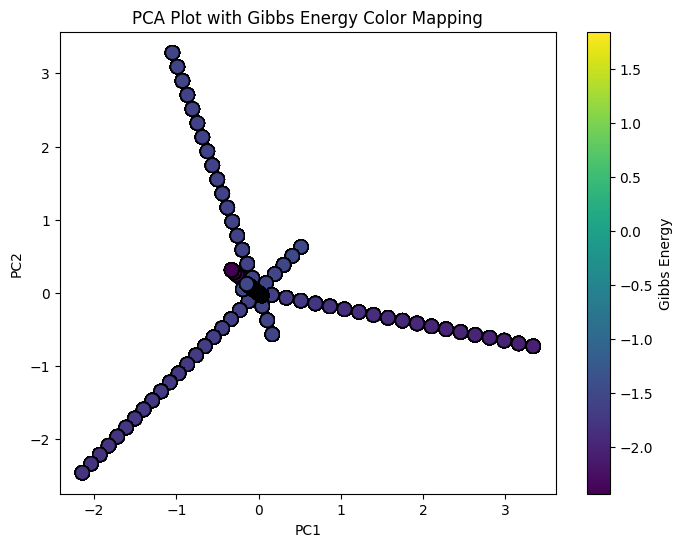

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load the CSV file
df = pd.read_csv('/home/couchbucks/Documents/saketh/regression/regression/pca_all.csv', delim_whitespace=True)

# Extract columns
pca1 = df['PC1']
pca2 = df['PC2']
gibbs_energy = df['Gibbs_energy']

# Create scatter plot
plt.figure(figsize=(8, 6))
scatter = plt.scatter(pca1, pca2, c=gibbs_energy, cmap='viridis', s=100, edgecolor='k')

# Add a colorbar
plt.colorbar(scatter, label='Gibbs Energy')

# Add labels and title
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA Plot with Gibbs Energy Color Mapping')

# Show plot
plt.show()


/tmp/ipykernel_156106/705684940.py:7: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv('/home/couchbucks/Documents/saketh/regression/regression/pca_all.csv', delim_whitespace=True)


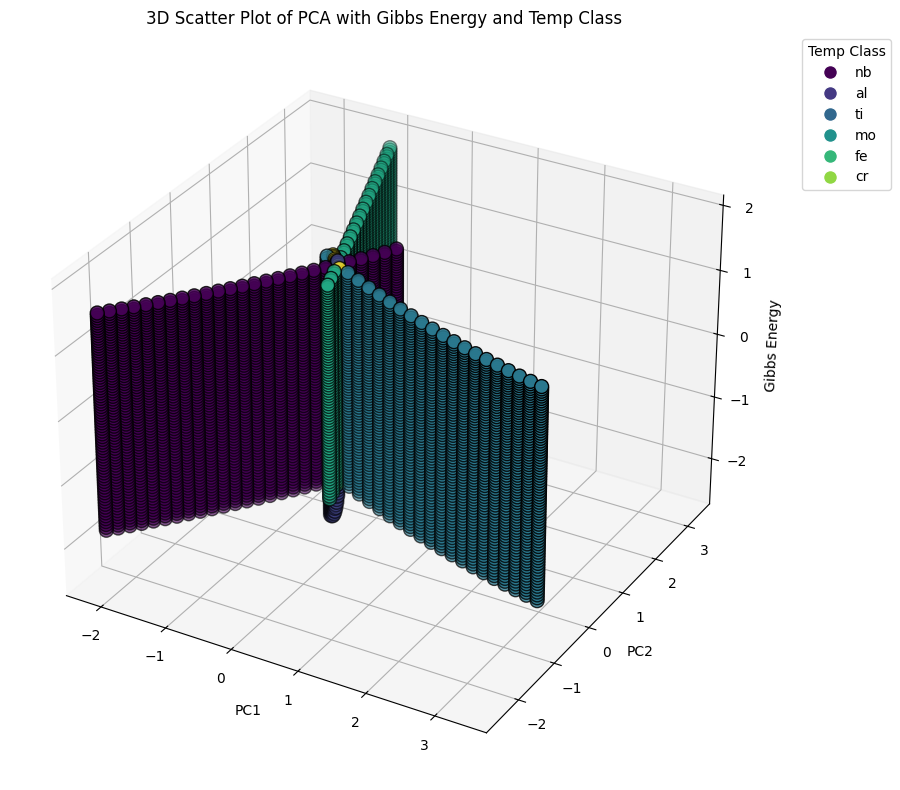

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# Load the CSV file
df = pd.read_csv('/home/couchbucks/Documents/saketh/regression/regression/pca_all.csv', delim_whitespace=True)

# Extract columns
pca1 = df['PC1']
pca2 = df['PC2']
gibbs_energy = df['Gibbs_energy']
temp_class = df['temp_class']

# Convert temp_class to numeric values
temp_class_unique = temp_class.unique()
temp_class_mapping = {cls: idx for idx, cls in enumerate(temp_class_unique)}
temp_class_numeric = temp_class.map(temp_class_mapping)

# Create a 3D scatter plot
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Create scatter plot
sc = ax.scatter(pca1, pca2, gibbs_energy, c=temp_class_numeric, cmap='viridis', s=100, edgecolor='k')

# Create legend
handles = []
for cls, idx in temp_class_mapping.items():
    handle = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=plt.get_cmap('viridis')(idx / len(temp_class_unique)), markersize=10, label=cls)
    handles.append(handle)

ax.legend(handles=handles, title='Temp Class', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add labels and title
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('Gibbs Energy')
ax.set_title('3D Scatter Plot of PCA with Gibbs Energy and Temp Class')

# Show plot
plt.tight_layout()
plt.show()


In [15]:
df

,Gibbs_energy\ttemp_class\tPC1\tPC2
0,1.8438879858697041\tnb\t0.5159498979579425\t0....
1,1.8074183691266417\tnb\t0.5159498979579425\t0....
2,1.7708092580907409\tnb\t0.5159498979579425\t0....
3,1.7340610928070896\tnb\t0.5159498979579425\t0....
4,1.6971747533658639\tnb\t0.5159498979579425\t0....
...,...
8176,-1.3441893903192697\tcr\t-0.1438877325785095\t...
8177,-1.3900420884698679\tcr\t-0.1438877325785095\t...
8178,-1.4359827956380298\tcr\t-0.1438877325785095\t...
8179,-1.482011511823755\tcr\t-0.1438877325785095\t0...


In [6]:
# from sklearn.decomposition import PCA
# import joblib  # For saving the PCA model
# import numpy as np

# # Extract points from scaled_ref_data_points
# scaled_points = np.array([x.point for x in scaled_ref_data_points])

# # Apply PCA
# pca = PCA(n_components=2)  # Adjust n_components as necessary
# pca_transformed_points = pca.fit_transform(scaled_points)

# # Save the PCA model to a file
# # joblib.dump(pca, 'pca_model.pkl')




In [7]:
def get_distances_from_query_ckdtree(query_points, closest_points, k):
    # Extract points from closest_points and convert to a NumPy array
    ref_points = np.array([point.point for point in closest_points])
    
    # Build the cKDTree from reference points
    tree = cKDTree(ref_points, leafsize=ref_points.shape[0] + 1)
    
    # Query the tree to find distances from each query_point to its k nearest neighbors
    distances, _ = tree.query(query_points, k=k, distance_upper_bound=np.inf)
    
    # Return the distances as a NumPy array of shape (n_query_points, k)
    return distances

def get_distances_and_closest_points_ckdtree(query_points, closest_points, k):
    # Extract points from closest_points and convert to a NumPy array
    ref_points = np.array([point.point for point in closest_points])
    
    # Build the cKDTree from reference points
    tree = cKDTree(ref_points, leafsize=ref_points.shape[0] + 1)
    
    # Query the tree to find distances and indices of the k nearest neighbors
    distances, indices = tree.query(query_points, k=k, distance_upper_bound=np.inf)
    
    # Use indices to extract the corresponding closest points
    closest_feature_matrix = ref_points[indices]
    
    # Return both distances and the closest feature matrix
    return distances, closest_feature_matrix

def get_distances_and_features_ckdtree(query_points, ref_points, k, all_gradients, all_gibbs_energies):
    # Build the cKDTree from reference points
    tree = cKDTree(ref_points, leafsize=ref_points.shape[0] + 1)
    
    # Query the tree to find distances and indices of the k nearest neighbors
    distances, indices = tree.query(query_points, k=k, distance_upper_bound=np.inf)
    
    # Extract the gradients and gibbs energies using the indices
    closest_feature_matrix = ref_points[indices]
    gradient_array = all_gradients[indices]
    gibbs_array = all_gibbs_energies[indices]
    
    # Return distances, gradients, and gibbs energies
    return distances, closest_feature_matrix, gradient_array, gibbs_array

In [8]:
only_points_query = np.array([x.point for x in scaled_remaining_data_points])

In [9]:
ref_points = np.array([point.point for point in gradient_points_ref])

In [10]:
distances, closest_points, gradient_array, gibbs_array = get_distances_and_features_ckdtree(only_points_query, 
                                                                                            ref_points, 
                                                                                            k=2,
                                                                                            all_gradients=all_gradients,
                                                                                            all_gibbs_energies=all_gibbs_energies
                                                                                            )

In [11]:
def calculate_weight_matrix(distances):
    # Add a small value to distances to avoid division by zero
    epsilon = 1e-6
    weights = 1 / (distances + epsilon)
    
    # Normalize the weights for each query point so that they sum to 1
    weights /= weights.sum(axis=1, keepdims=True)
    
    return weights

weights = calculate_weight_matrix(distances)

In [12]:
weights.shape

(1637, 2)

In [85]:
# Function to predict Gibbs energy using weighted directional derivatives
def weighted_predict_with_directional_derivatives(query_point, closest_points, distances, weighted=True):
    
    # print(distances.shape)
    
    weights = 1 / (distances + 1e-6)  # Avoid division by zero
    weights /= weights.sum()  # Normalize weights

    unweighted_preds = []
    
    # query_point = np.array(query_point)
    
    # print(weights)
    
    # start = time.time()
    
    # start = None
    # end = None
    
    for point in closest_points:

        closest_point = point.point
        # point_dict = {variables[j]: closest_point[j] for j in range(len(variables))}
        
        gradient_at_closest = point.gradient # array of size [n_features x 1]
        
        direction = query_point - closest_point # vector of size [n_features]
        # formal way to do it:
        # change_gibbs = D uf(x 0,y 0)⋅∣∣v∣∣
        # direction_unit_vector = direction / np.linalg.norm(direction)
        
        # directional_derivative = np.dot(direction_unit_vector, gradient_at_closest)
        
        # directional_derivative_distance = np.linalg.norm(direction)
        # change_gibbs = directional_derivative * directional_derivative_distance
        
        
        # cheap way:
        change_gibbs = np.dot(direction, gradient_at_closest) # one value
        
        pred_gibbs_energy_point = point.gibbs_energy + change_gibbs
        
        unweighted_preds.append(pred_gibbs_energy_point)
        # end_cpy = time.time()
        # end = time.time()
        
        # print(end - start)
        
        # exit()
        
    unweighted_preds = np.array(unweighted_preds)
    
    # print(unweighted_preds)
    # print(weights)
    
    to_return = np.dot(unweighted_preds, weights)
    
    # print(unweighted_preds.shape)
    # print(weights.shape)
    
    if weighted:
        # return to_return, start, end
        return to_return
    
    else:
        return sum(unweighted_preds)/len(unweighted_preds)

# Example usage of the prediction function
all_preds = []
actual = []


# with cProfile.Profile() as pr:
    
# Loop through the remaining data points for predictions
for x in scaled_remaining_data_points:
    # start = time.perf_counter()
    
    scaled_query = x.point
    
    pca_query = pca.transform(scaled_query.reshape(1, -1))

    # closest_points = get_closest_points_by_element(scaled_query, scaled_ref_data_points, n=7, variables=relevant_variables)
    # closest_points, distances = get_closest_points(scaled_query, gradient_points_ref, n=2)
    # closest_points, distances = get_closest_points_sklearn(scaled_query, gradient_points_ref, n=2)
    closest_points, distances = get_closest_points_ckdtree(scaled_query, gradient_points_ref, n=2)
    # closest_points, distances = get_closest_points_faiss(scaled_query, gradient_points_ref, n=2)
    
    # closest_points, distances, indices = get_closest_points_ckdtree_pca(pca_query, gradient_points_ref, n=2, return_indices=True)
    
    # to_calculate_distances_points = [gradient_points_ref[i].point for i in indices]
    # distances = np.array([calculate_distance(scaled_query, ref) for ref in to_calculate_distances_points])
    
    # predicted_gibbs_energy, start, end = weighted_predict_with_directional_derivatives(scaled_query, closest_points, gradients, relevant_variables, weighted=True)
    predicted_gibbs_energy = weighted_predict_with_directional_derivatives(scaled_query, closest_points, distances, weighted=True)
    
    all_preds.append(predicted_gibbs_energy)
    actual.append(x.gibbs_energy)
    

In [ ]:
pca.transform(scaled_ref_data_points[0].point.reshape(1, -1))

array([[-0.17496541,  0.13076114]])

In [151]:
def predict_gibbs_energy_arrays(query_points, closest_features, distances, gradients, gibbs_energies, weights, weighted=True):
    # Calculate the directions (query_points - closest_points) for each query point
    directions = query_points[:, np.newaxis, :] - closest_features  # (n_query x k x n_features)
    
    # Calculate the change in Gibbs energy using the dot product of directions and gradients
    change_gibbs = np.einsum('ijk,ijk->ij', directions, gradients)  # (n_query x k)
    
    # Predict Gibbs energy for each closest point
    pred_gibbs_energy = gibbs_energies + change_gibbs  # (n_query x k)
    
    # Calculate the final weighted predictions
    if weighted:
        predictions = np.einsum('ij,ij->i', pred_gibbs_energy, weights)  # Weighted sum (n_query,)
    else:
        predictions = pred_gibbs_energy.mean(axis=1)  # Unweighted mean (n_query,)
    
    return predictions

In [ ]:
distances, closest_points, gradient_array, gibbs_array = get_distances_and_features_ckdtree(only_points_query, 
                                                                                            ref_points, 
                                                                                            k=2,
                                                                                            all_gradients=all_gradients,
                                                                                            all_gibbs_energies=all_gibbs_energies
                                                                                            )

In [153]:
predictions = predict_gibbs_energy_arrays(
    only_points_query, closest_points, distances, gradient_array, gibbs_array, weights, weighted=True
)

(1637, 2, 8)
(1637, 2, 8)


In [157]:
predictions.shape
actual = np.array([x.gibbs_energy for x in scaled_remaining_data_points])

In [159]:
predictions.shape

(1637,)

In [110]:
# Function to predict Gibbs energy using weighted directional derivatives
def weighted_predict_with_directional_derivatives(query_point, closest_points, distances, weighted=True):
    
    # print(distances.shape)
    
    weights = 1 / (distances + 1e-6)  # Avoid division by zero
    weights /= weights.sum()  # Normalize weights

    unweighted_preds = []
    
    # query_point = np.array(query_point)
    
    # print(weights)
    
    # start = time.time()
    
    # start = None
    # end = None
    
    for point in closest_points:

        closest_point = point.point
        # point_dict = {variables[j]: closest_point[j] for j in range(len(variables))}
        
        gradient_at_closest = point.gradient # array of size [n_features x 1]
        
        direction = query_point - closest_point # vector of size [n_features]
        # formal way to do it:
        # change_gibbs = D uf(x 0,y 0)⋅∣∣v∣∣
        # direction_unit_vector = direction / np.linalg.norm(direction)
        
        # directional_derivative = np.dot(direction_unit_vector, gradient_at_closest)
        
        # directional_derivative_distance = np.linalg.norm(direction)
        # change_gibbs = directional_derivative * directional_derivative_distance
        
        
        # cheap way:
        change_gibbs = np.dot(direction, gradient_at_closest) # one value
        
        pred_gibbs_energy_point = point.gibbs_energy + change_gibbs
        
        unweighted_preds.append(pred_gibbs_energy_point)
        # end_cpy = time.time()
        # end = time.time()
        
        # print(end - start)
        
        # exit()
        
    unweighted_preds = np.array(unweighted_preds)
    
    # print(unweighted_preds)
    # print(weights)
    
    to_return = np.dot(unweighted_preds, weights)
    
    # print(unweighted_preds.shape)
    # print(weights.shape)
    
    if weighted:
        # return to_return, start, end
        return to_return
    
    else:
        return sum(unweighted_preds)/len(unweighted_preds)

# Example usage of the prediction function
all_preds = []
actual = []


# with cProfile.Profile() as pr:
    
# Loop through the remaining data points for predictions
for x in scaled_remaining_data_points:
    # start = time.perf_counter()
    
    scaled_query = x.point
    
    pca_query = pca.transform(scaled_query.reshape(1, -1))

    # closest_points = get_closest_points_by_element(scaled_query, scaled_ref_data_points, n=7, variables=relevant_variables)
    # closest_points, distances = get_closest_points(scaled_query, gradient_points_ref, n=2)
    # closest_points, distances = get_closest_points_sklearn(scaled_query, gradient_points_ref, n=2)
    closest_points, distances = get_closest_points_ckdtree(scaled_query, gradient_points_ref, n=2)
    # closest_points, distances = get_closest_points_faiss(scaled_query, gradient_points_ref, n=2)
    
    # closest_points, distances, indices = get_closest_points_ckdtree_pca(pca_query, gradient_points_ref, n=2, return_indices=True)
    
    # to_calculate_distances_points = [gradient_points_ref[i].point for i in indices]
    # distances = np.array([calculate_distance(scaled_query, ref) for ref in to_calculate_distances_points])
    
    # predicted_gibbs_energy, start, end = weighted_predict_with_directional_derivatives(scaled_query, closest_points, gradients, relevant_variables, weighted=True)
    predicted_gibbs_energy = weighted_predict_with_directional_derivatives(scaled_query, closest_points, distances, weighted=True)
    
    all_preds.append(predicted_gibbs_energy)
    actual.append(x.gibbs_energy)
    

In [105]:
vars(scaled_remaining_data_points[0])

{'point': array([-1.58248801, -1.37972892, -0.28569887, -0.40870239, -0.36739668,
        -0.05160851, -0.17921157,  0.        ]),
 'index': 3,
 'temp_class': 'nb',
 'gibbs_energy': np.float64(1.7340610928070896)}

In [160]:
un_float_actual = [float(x) for x in actual]


def mean_absolute_error_numpy(y_true, y_pred, decimals=8):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    if y_true.shape != y_pred.shape:
        raise ValueError("The lists must have the same shape.")
    
    # Mean Absolute Error
    absolute_errors = np.abs(y_true - y_pred)
    # print(absolute_errors)
    
    mae = np.mean(absolute_errors)
    mae_stdev = np.std(absolute_errors)
    
    # Mean Absolute Percentage Error
    # Avoid division by zero
    non_zero_indices = y_true != 0
    abs_percentage_errors = np.abs((y_true[non_zero_indices] - y_pred[non_zero_indices]) / y_true[non_zero_indices])
    mape = np.mean(abs_percentage_errors)
    mape_stdev = np.std(abs_percentage_errors)
    
    print('To 2 stdevs:')
    
    # Print results
    
    print(f"Mean Absolute Error (MAE): {mae:.{decimals}f} ± {2 * mae_stdev:.{decimals}f}")
    print(f"Mean Absolute Percentage Error (MAPE): {mape:.{decimals}f} ± {2 * mape_stdev:.{decimals}f}")

    return mae, mae_stdev, mape, mape_stdev

mae, mae_stdev, mape, mape_stdev = mean_absolute_error_numpy(predictions, actual)

To 2 stdevs:
Mean Absolute Error (MAE): 0.00042608 ± 0.00228926
Mean Absolute Percentage Error (MAPE): 0.03914235 ± 3.03854161
